# 01 - Explore the January 2025 Yellow Taxi data

**Goal:** understand the data well enough to decide (a) how to define the target `duration`, (b) which rows to drop, and (c) which columns may be used as features.
This notebook is exploration only. The decisions made here are moved into `src/` as the data pipeline afterwards.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

RAW = Path("../data/raw/yellow_tripdata_2025-01.parquet")
df = pd.read_parquet(RAW)
df.shape

(3475226, 20)

## 1. First look: columns, types, missing values

In [2]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.00,1.60,1.00,N,229,237,1,10.00,3.50,0.50,3.00,0.00,1.00,18.00,2.50,0.00,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.00,0.50,1.00,N,236,237,1,5.10,3.50,0.50,2.02,0.00,1.00,12.12,2.50,0.00,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.00,0.60,1.00,N,141,141,1,5.10,3.50,0.50,2.00,0.00,1.00,12.10,2.50,0.00,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.00,0.52,1.00,N,244,244,2,7.20,1.00,0.50,0.00,0.00,1.00,9.70,0.00,0.00,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.00,0.66,1.00,N,244,116,2,5.80,1.00,0.50,0.00,0.00,1.00,8.30,0.00,0.00,0.00


In [3]:
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_share": df.isna().mean(), "n_unique": df.nunique()})
overview

,dtype,missing_share,n_unique
VendorID,int32,0.00,4
tpep_pickup_datetime,datetime64[us],0.00,1672077
tpep_dropoff_datetime,datetime64[us],0.00,1671993
passenger_count,float64,0.16,10
trip_distance,float64,0.00,4545
RatecodeID,float64,0.16,7
store_and_fwd_flag,str,0.16,2
PULocationID,int32,0.00,261
DOLocationID,int32,0.00,260
payment_type,int64,0.00,6


Five columns share the same missing share (`passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee`). That suggests a block of rows where those fields were never filled in. Check whether it is the same rows.

In [4]:
cols = ["passenger_count", "RatecodeID", "store_and_fwd_flag", "congestion_surcharge", "Airport_fee"]
print("rows with all five missing:", df[cols].isna().all(axis=1).mean().round(4))
print("rows with any of five missing:", df[cols].isna().any(axis=1).mean().round(4))

rows with all five missing: 0.1554
rows with any of five missing: 0.1554


## 2. Define the target: `duration`

`duration` = dropoff time minus pickup time, in **minutes**. This is the number we will predict.

In [5]:
df["duration"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df["duration"].describe(percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

count   3,475,226.00
mean           15.02
std            38.71
min       -51,472.32
0.1%            0.07
1%              0.67
5%              3.37
50%            11.70
95%            36.20
99%            58.92
99.9%          98.26
max         5,626.32
Name: duration, dtype: float64

The extremes (negative values, days-long trips) would dominate a plot and the RMSE. Look at how many rows sit outside a sensible range.

In [6]:
checks = {
    "duration <= 0": (df["duration"] <= 0).sum(),
    "duration < 1 min": (df["duration"] < 1).sum(),
    "duration > 60 min": (df["duration"] > 60).sum(),
    "duration > 120 min": (df["duration"] > 120).sum(),
    "duration > 24 h": (df["duration"] > 24 * 60).sum(),
}
pd.Series(checks).to_frame("rows").assign(share=lambda t: t["rows"] / len(df))

,rows,share
duration <= 0,2051,0.00
duration < 1 min,40111,0.01
duration > 60 min,31867,0.01
duration > 120 min,2014,0.00
duration > 24 h,20,0.00


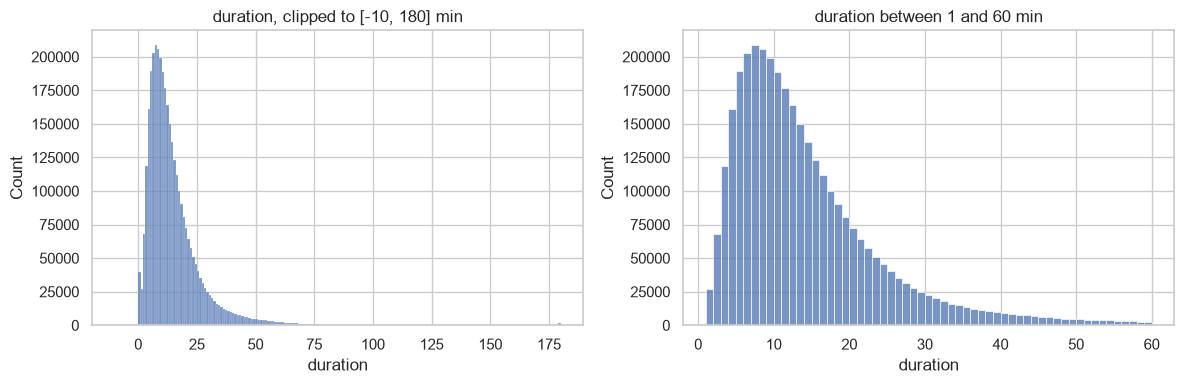

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["duration"].clip(-10, 180), bins=190, ax=axes[0])
axes[0].set_title("duration, clipped to [-10, 180] min")
sns.histplot(df.loc[df["duration"].between(1, 60), "duration"], bins=59, ax=axes[1])
axes[1].set_title("duration between 1 and 60 min")
plt.tight_layout()

## 3. Other suspicious values

In [8]:
df[["trip_distance", "fare_amount", "total_amount", "passenger_count"]].describe(percentiles=[0.01, 0.5, 0.99, 0.999])

,trip_distance,fare_amount,total_amount,passenger_count
count,"3,475,226.00","3,475,226.00","3,475,226.00","2,935,077.00"
mean,5.86,17.08,25.61,1.30
std,564.60,463.47,463.66,0.75
min,0.00,-900.00,-901.00,0.00
1%,0.00,-10.70,-15.70,1.00
50%,1.67,12.11,19.95,1.00
99%,19.50,72.30,102.92,5.00
99.9%,28.86,132.00,163.98,6.00
max,"276,423.57","863,372.12","863,380.37",9.00


In [9]:
checks = {
    "trip_distance == 0": (df["trip_distance"] == 0).sum(),
    "trip_distance > 100 miles": (df["trip_distance"] > 100).sum(),
    "passenger_count == 0": (df["passenger_count"] == 0).sum(),
    "passenger_count > 6": (df["passenger_count"] > 6).sum(),
    "fare_amount <= 0": (df["fare_amount"] <= 0).sum(),
}
pd.Series(checks).to_frame("rows").assign(share=lambda t: t["rows"] / len(df))

,rows,share
trip_distance == 0,90893,0.03
trip_distance > 100 miles,162,0.00
passenger_count == 0,24656,0.01
passenger_count > 6,18,0.00
fare_amount <= 0,145516,0.04


The monthly file can also contain trips from other months (we saw this in the Green Taxi project).

In [10]:
print(df["tpep_pickup_datetime"].min(), "->", df["tpep_pickup_datetime"].max())
df["tpep_pickup_datetime"].dt.to_period("M").value_counts().sort_index()

2024-12-31 20:47:55 -> 2025-02-01 00:00:44


tpep_pickup_datetime
2024-12         21
2025-01    3475204
2025-02          1
Freq: M, Name: count, dtype: int64

## 4. Does the data carry signal for duration?

Take plausible trips (1 to 120 min) and check the relationships we hope the model can use: distance, hour of day, weekday, locations.

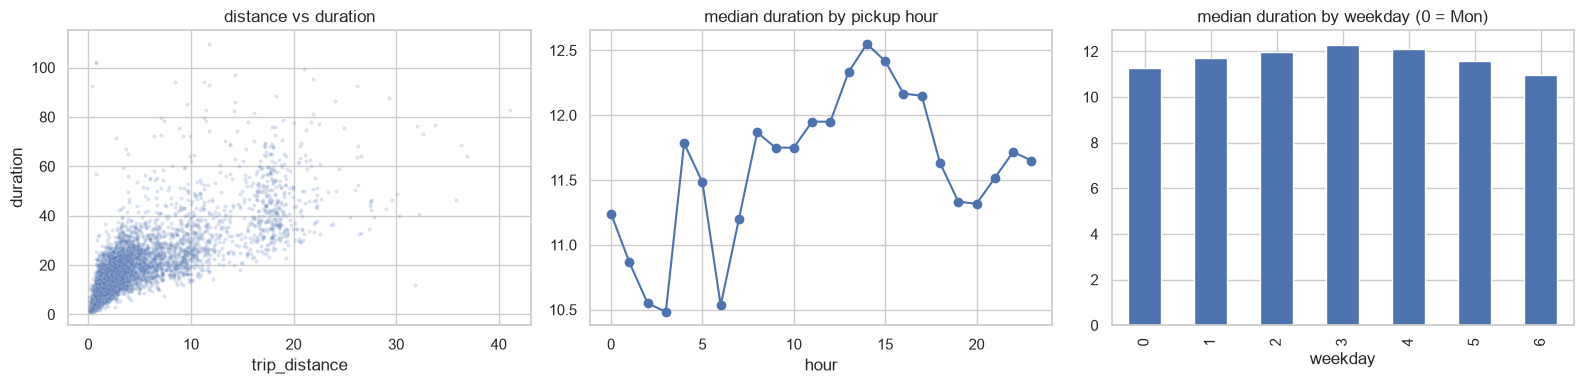

In [11]:
ok = df[df["duration"].between(1, 120) & df["trip_distance"].between(0.1, 50)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=ok.sample(10_000, random_state=1), x="trip_distance", y="duration", alpha=0.2, s=8, ax=axes[0])
axes[0].set_title("distance vs duration")
ok.groupby(ok["tpep_pickup_datetime"].dt.hour)["duration"].median().plot(ax=axes[1], marker="o")
axes[1].set(title="median duration by pickup hour", xlabel="hour")
ok.groupby(ok["tpep_pickup_datetime"].dt.day_of_week)["duration"].median().plot(kind="bar", ax=axes[2])
axes[2].set(title="median duration by weekday (0 = Mon)", xlabel="weekday")
plt.tight_layout()

In [12]:
print("correlation distance / duration:", round(ok["trip_distance"].corr(ok["duration"]), 3))
print("PULocationID unique:", df["PULocationID"].nunique(), "| DOLocationID unique:", df["DOLocationID"].nunique())
top20 = df.groupby(["PULocationID", "DOLocationID"]).size().nlargest(20).sum() / len(df)
print("share of trips covered by the 20 most common PU->DO pairs:", round(top20, 3))

correlation distance / duration: 0.805
PULocationID unique: 261 | DOLocationID unique: 260
share of trips covered by the 20 most common PU->DO pairs: 0.064


## 5. Which columns may be used as features? (leakage check)

The API will be called **before the trip is over**, so it can only send what is known at pickup time. Anything that is only known after the trip ends would let the model "cheat" in training but cannot be provided in production.

| Column | Known at pickup? | Use as feature? |
|---|---|---|
| `tpep_pickup_datetime` | yes | yes, as hour / weekday |
| `PULocationID`, `DOLocationID` | yes (customer states destination) | yes |
| `passenger_count` | yes | yes |
| `trip_distance` | **no**, measured by the meter during the trip | see note below |
| `tpep_dropoff_datetime` | **no** | no, it defines the target |
| `fare_amount`, `total_amount`, `tip_amount`, `tolls_amount`, surcharges, `extra`, `mta_tax` | **no**, depend on the trip | no |
| `payment_type` | no, settled at the end | no |
| `RatecodeID`, `store_and_fwd_flag`, `VendorID` | partly / not informative | decide later |

**Note on `trip_distance`:** it is by far the strongest predictor, but strictly speaking it is only known after the trip. This is a decision for the project README: start with a baseline that uses `trip_distance`, and document the limitation (or compare with a model without it).

## 6. Candidate cleaning rules, and how many rows each flags

In [13]:
rules = {
    "pickup outside January 2025": ~df["tpep_pickup_datetime"].between("2025-01-01", "2025-02-01", inclusive="left"),
    "duration not in [1, 60] min": ~df["duration"].between(1, 60),
    "trip_distance not in (0, 100]": ~((df["trip_distance"] > 0) & (df["trip_distance"] <= 100)),
    "missing passenger_count": df["passenger_count"].isna(),
}
report = pd.DataFrame({"rows_flagged": {k: int(v.sum()) for k, v in rules.items()}})
report["share"] = report["rows_flagged"] / len(df)
any_rule = pd.concat(rules.values(), axis=1).any(axis=1)
print(f"rows kept after all rules: {(~any_rule).sum():,} of {len(df):,} ({(~any_rule).mean():.1%})")
report

rows kept after all rules: 2,852,634 of 3,475,226 (82.1%)


,rows_flagged,share
pickup outside January 2025,22,0.00
"duration not in [1, 60] min",71978,0.02
"trip_distance not in (0, 100]",91055,0.03
missing passenger_count,540149,0.16


## 7. Decisions (to be implemented in `src/`)

1. **Target:** `duration` in minutes = dropoff minus pickup.
2. **Drop** rows with pickup outside January 2025, `duration` outside [1, 60] min, and `trip_distance` outside (0, 100] miles.
3. **Do not drop** rows with a missing `passenger_count` (15.5% of the data, one block of rows where five meter fields are empty). Dropping them would cost 540k rows; instead fill with the median (1) in the feature step.
4. **Features:** pickup hour, pickup weekday, `PULocationID`, `DOLocationID`, `passenger_count`, `trip_distance` (with the leakage caveat above).
5. Distance correlates strongly with duration (r = 0.81), so a baseline should already work well.

The same findings are written up in the README section *Exploration findings*.